# 02 · Lagrange Multipliers, Linear Programming, Duality and Games

**Thesis reference:** Chapter 1, Sections 1.2 (*Lagrange Multipliers = Derivatives of the Cost*) and 1.3 (*Linear Programming, Game Theory and Duality*).

Contents:
1. Minimizing a quadratic with linear constraints by solving the KKT system, and checking that **the multiplier is the derivative of the optimal cost**.
2. A linear program and its **dual**: both reach the same optimal value (strong duality), and complementary slackness holds.
3. **Max flow = min cut** on a small network.
4. **Two-person zero-sum games** solved by linear programming, where minimax = maximin (von Neumann).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from scipy.optimize import linprog, minimize
from pathlib import Path

FIG = Path("..") / "figures"
FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
np.set_printoptions(precision=4, suppress=True)

## 1. Quadratic cost with linear constraints

Minimize $\tfrac12 x^T S x$ subject to $Ax = b$. With the Lagrangian
$L(x,\lambda) = \tfrac12 x^TSx + \lambda^T(Ax-b)$, setting the derivatives to zero gives the **KKT system**

$$\begin{bmatrix} S & A^T \\ A & 0 \end{bmatrix}\begin{bmatrix} x \\ \lambda \end{bmatrix} = \begin{bmatrix} 0 \\ b \end{bmatrix}.$$

The optimal cost is $C(b) = \tfrac12 b^T (AS^{-1}A^T)^{-1} b$, and $\dfrac{\partial C}{\partial b} = -\lambda$:
the multiplier measures how fast the cost changes when the constraint moves.

In [2]:
rng = np.random.default_rng(1)
n, m = 5, 2
M = rng.standard_normal((n, n))
S = M @ M.T + n * np.eye(n)            # symmetric positive definite
A = rng.standard_normal((m, n))
b = np.array([1.0, -2.0])

KKT = np.block([[S, A.T], [A, np.zeros((m, m))]])
sol = np.linalg.solve(KKT, np.r_[np.zeros(n), b])
x_star, lam = sol[:n], sol[n:]
cost = lambda x: 0.5 * x @ S @ x

# check against a general-purpose constrained solver
res = minimize(cost, np.zeros(n), constraints={"type": "eq", "fun": lambda x: A @ x - b}, method="SLSQP")
print("KKT solution     x* =", x_star)
print("SLSQP solution   x  =", res.x)
print("constraint residual  ", A @ x_star - b)

# dC/db by finite differences vs -lambda
def optimal_cost(bb):
    s = np.linalg.solve(KKT, np.r_[np.zeros(n), bb])
    return cost(s[:n])

eps = 1e-6
dC = np.array([(optimal_cost(b + eps * e) - optimal_cost(b - eps * e)) / (2 * eps) for e in np.eye(m)])
print("\nfinite-difference dC/db =", dC)
print("-lambda                 =", -lam)

KKT solution     x* = [-0.5928  0.1358  0.0191 -0.2304 -0.1788]
SLSQP solution   x  = [-0.5928  0.1358  0.0191 -0.2304 -0.1788]
constraint residual   [ 0. -0.]

finite-difference dC/db = [ 1.2487 -1.0635]
-lambda                 = [ 1.2487 -1.0635]


## 2. Linear programming and duality: a diet problem

**Primal.** Buy amounts $x_1, x_2 \ge 0$ of two foods costing 2 and 3 per unit. We need at least 4 units of protein ($x_1 + 2x_2 \ge 4$) and 6 units of vitamins ($3x_1 + x_2 \ge 6$):
$$\min\; 2x_1 + 3x_2 \quad \text{s.t. } Ax \ge b,\; x \ge 0.$$

**Dual.** A seller prices protein and vitamin pills at $y_1, y_2 \ge 0$ and maximizes revenue without being more expensive than either food:
$$\max\; 4y_1 + 6y_2 \quad \text{s.t. } A^T y \le c,\; y \ge 0.$$

The weak duality inequality $b^Ty \le c^Tx$ becomes an equality at the optimum.

In [3]:
c = np.array([2.0, 3.0])
A_lp = np.array([[1.0, 2.0], [3.0, 1.0]])
b_lp = np.array([4.0, 6.0])

primal = linprog(c, A_ub=-A_lp, b_ub=-b_lp, bounds=[(0, None)] * 2, method="highs")
dual = linprog(-b_lp, A_ub=A_lp.T, b_ub=c, bounds=[(0, None)] * 2, method="highs")
x_lp, y_lp = primal.x, dual.x

print(f"primal optimum x* = {x_lp},  cost   c·x = {c @ x_lp:.4f}")
print(f"dual   optimum y* = {y_lp},  value  b·y = {b_lp @ y_lp:.4f}")
print("complementary slackness  x_j (c - A^T y)_j =", x_lp * (c - A_lp.T @ y_lp))
print("                         y_i (A x - b)_i   =", y_lp * (A_lp @ x_lp - b_lp))

primal optimum x* = [1.6 1.2],  cost   c·x = 6.8000
dual   optimum y* = [1.4 0.2],  value  b·y = 6.8000
complementary slackness  x_j (c - A^T y)_j = [0. 0.]
                         y_i (A x - b)_i   = [0. 0.]


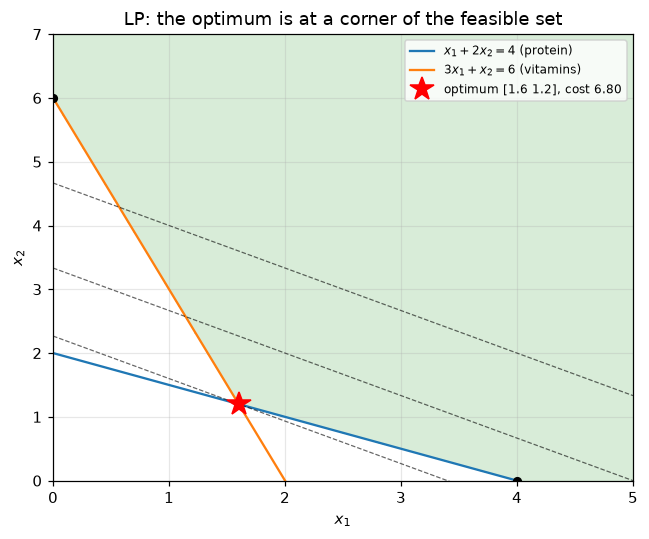

In [4]:
x1 = np.linspace(0, 5, 400)
fig, ax = plt.subplots(figsize=(6, 5))
X1, X2 = np.meshgrid(x1, np.linspace(0, 7, 400))
feasible = (X1 + 2 * X2 >= 4) & (3 * X1 + X2 >= 6)
ax.contourf(X1, X2, feasible, levels=[0.5, 1], colors=["#cfe8cf"], alpha=0.8)
ax.plot(x1, (4 - x1) / 2, label=r"$x_1 + 2x_2 = 4$ (protein)")
ax.plot(x1, 6 - 3 * x1, label=r"$3x_1 + x_2 = 6$ (vitamins)")
for level in [c @ x_lp, 10, 14]:
    ax.plot(x1, (level - 2 * x1) / 3, "k--", lw=0.8, alpha=0.6)
ax.plot(*x_lp, "r*", ms=16, label=f"optimum {x_lp.round(2)}, cost {c @ x_lp:.2f}")
for v in [(0, 6), (4, 0)]:
    ax.plot(*v, "ko", ms=5)
ax.set_xlim(0, 5); ax.set_ylim(0, 7)
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
ax.set_title("LP: the optimum is at a corner of the feasible set")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "02_linear_program.png", bbox_inches="tight")
plt.show()

## 3. Max flow = min cut

The maximum flow from source $s$ to sink $t$ equals the minimum total capacity of edges that must be cut to separate them.
This is LP duality again: max-flow is the primal and min-cut is the dual.

max flow value : 28
min cut value  : 28
cut edges      : [('s', 'a'), ('b', 'd'), ('f', 't')]


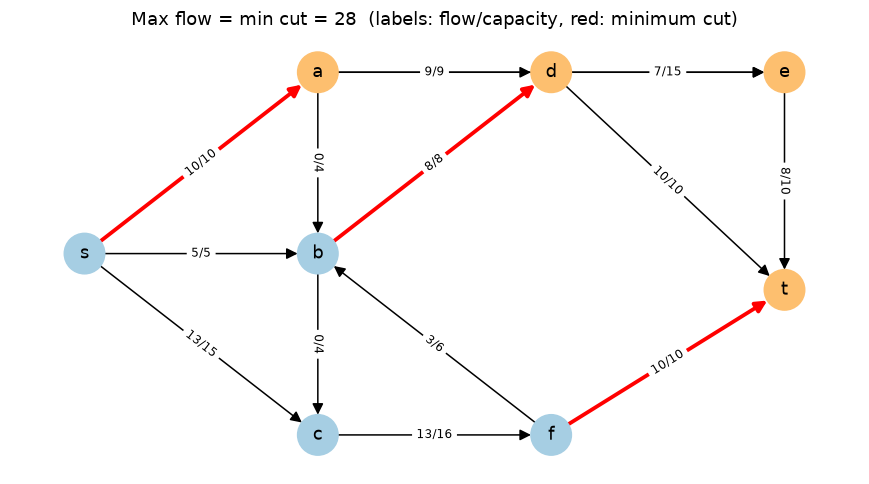

In [5]:
G = nx.DiGraph()
edges = [("s", "a", 10), ("s", "b", 5), ("s", "c", 15), ("a", "b", 4), ("a", "d", 9), ("a", "e", 15),
         ("b", "c", 4), ("b", "d", 8), ("c", "f", 16), ("d", "e", 15), ("d", "t", 10), ("e", "t", 10),
         ("f", "b", 6), ("f", "t", 10)]
G.add_weighted_edges_from(edges, weight="capacity")

flow_value, flow = nx.maximum_flow(G, "s", "t")
cut_value, (S_side, T_side) = nx.minimum_cut(G, "s", "t")
cut_edges = [(u, v) for u, v in G.edges if u in S_side and v in T_side]
print("max flow value :", flow_value)
print("min cut value  :", cut_value)
print("cut edges      :", cut_edges)

pos = {"s": (0, 1), "a": (1, 2), "b": (1, 1), "c": (1, 0), "d": (2, 2), "f": (2, 0), "e": (3, 2), "t": (3, 0.8)}
plt.figure(figsize=(8, 4.5))
nx.draw_networkx_nodes(G, pos, node_color=["#a6cee3" if n in S_side else "#fdbf6f" for n in G], node_size=700)
nx.draw_networkx_labels(G, pos)
nx.draw_networkx_edges(G, pos, edgelist=[e for e in G.edges if e not in cut_edges], arrowsize=15, node_size=700)
nx.draw_networkx_edges(G, pos, edgelist=cut_edges, edge_color="red", width=2.5, arrowsize=15, node_size=700)
nx.draw_networkx_edge_labels(G, pos, edge_labels={(u, v): f"{flow[u][v]}/{d['capacity']}" for u, v, d in G.edges(data=True)},
                             font_size=8)
plt.title(f"Max flow = min cut = {flow_value}  (labels: flow/capacity, red: minimum cut)")
plt.axis("off")
plt.tight_layout()
plt.savefig(FIG / "02_max_flow_min_cut.png", bbox_inches="tight")
plt.show()

## 4. Two-person zero-sum games

The row player picks row $i$ and the column player picks column $j$; the column player pays $M_{ij}$ to the row player.
With mixed strategies $p$ (rows) and $q$ (columns), von Neumann's minimax theorem says

$$\max_p \min_q\; p^T M q \;=\; \min_q \max_p\; p^T M q \;=\; v.$$

Each side is a linear program, and the two LPs are duals of each other.

In [6]:
def solve_game(M):
    """Return (p, q, v): optimal mixed strategies and the game value."""
    M = np.asarray(M, float)
    r, k = M.shape
    # row player: maximize v  s.t.  (M^T p)_j >= v,  sum p = 1,  p >= 0
    row = linprog(np.r_[np.zeros(r), -1.0],
                  A_ub=np.c_[-M.T, np.ones(k)], b_ub=np.zeros(k),
                  A_eq=[np.r_[np.ones(r), 0.0]], b_eq=[1.0],
                  bounds=[(0, None)] * r + [(None, None)], method="highs")
    # column player: minimize w  s.t.  (M q)_i <= w,  sum q = 1,  q >= 0
    col = linprog(np.r_[np.zeros(k), 1.0],
                  A_ub=np.c_[M, -np.ones(r)], b_ub=np.zeros(r),
                  A_eq=[np.r_[np.ones(k), 0.0]], b_eq=[1.0],
                  bounds=[(0, None)] * k + [(None, None)], method="highs")
    return row.x[:r], col.x[:k], row.x[-1], col.x[-1]

games = {
    "2x2 game  [[3,-1],[-2,1]]": [[3, -1], [-2, 1]],
    "Rock-Paper-Scissors": [[0, -1, 1], [1, 0, -1], [-1, 1, 0]],
}
for name, M in games.items():
    p, q, maximin, minimax = solve_game(M)
    print(f"{name}\n  p* = {p}   q* = {q}\n  maximin = {maximin:.4f}   minimax = {minimax:.4f}\n")

print("2x2 check by hand: p* = (3/7, 4/7) =", np.array([3, 4]) / 7, ", value = 1/7 =", round(1 / 7, 4))

2x2 game  [[3,-1],[-2,1]]
  p* = [0.4286 0.5714]   q* = [0.2857 0.7143]
  maximin = 0.1429   minimax = 0.1429

Rock-Paper-Scissors
  p* = [0.3333 0.3333 0.3333]   q* = [0.3333 0.3333 0.3333]
  maximin = -0.0000   minimax = -0.0000

2x2 check by hand: p* = (3/7, 4/7) = [0.4286 0.5714] , value = 1/7 = 0.1429


### Takeaways
* Lagrange multipliers are sensitivities (shadow prices): $\partial C/\partial b = -\lambda$.
* Every LP has a dual with the same optimal value. Max-flow/min-cut and minimax games are both instances of this duality.
* The same ideas reappear in machine learning: the dual of a support vector machine, constrained training, and adversarial (min-max) objectives such as GANs.